# Exploring the data

Sam Strickler - Honors research project - [Home Credit Default Risk](https://www.kaggle.com/competitions/home-credit-default-risk) (Kaggle)

The first of three notebooks. It looks at the data, saves the table 02_research starts from,
and writes the numbers for the website's findings page.

1. **01_eda** (this one): what the applications look like (exploratory data analysis)
2. **02_research**: the first models, what improved them, and what a form can see.
3. **03_train**: trains and saves the model weights the website uses.

## Three things to know about the data

**These are not home loans.** Home Credit is the lender's name. It sells small consumer
loans. About half of its past loans were point-of-sale credit, mostly for phones and
electronics, and the median loan runs 12 months.

**Income and payments are monthly.** The dataset doesn't say so, but the arithmetic does.
The median payment is 24,903 and the median income is 147,150, so a payment is about 17% of
income. If that income were yearly, the payment would be twice what the applicant earns in
a month.

**`TARGET` is an early late payment, not a lost loan.** It is 1 when one of the first few
payments arrived more than a few days late. That happened to 8.07% of applicants. The data
don't say whether those loans were eventually repaid. So this is an early-warning model, and "missed a payment"
in these notebooks means that early stumble.

Amounts are in an unnamed currency. That doesn't affect the model, because trees only
compare values and the strongest features are ratios.

In [1]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Earth palette, shared with the website
earth_palette = [
    "#6b8f71",  # sage green
    "#8b5a2b",  # warm brown
    "#3b5c8a",  # muted deep blue
    "#e0b44c",  # warm earthy yellow
    "#8c2b2b",  # dark red
]
sns.set_theme(
    style="whitegrid",
    rc={
        "axes.facecolor": "#f2ede6",
        "figure.facecolor": "#f2ede6",
        "axes.edgecolor": "#3b342b",
        "grid.color": "#d0c4b4",
        "axes.labelcolor": "#222222",
        "xtick.color": "#222222",
        "ytick.color": "#222222",
    },
)
sns.set_palette(earth_palette)

# How the outcome is labelled on every chart
OUTCOME = {0: "Repaid on time", 1: "Missed a payment"}

# Charts the paper uses are also saved here
FIGURES = "figures"
os.makedirs(FIGURES, exist_ok=True)

## 1. Load the application table

In [2]:
df = pd.read_csv("../data/application_train.csv")
df.shape

(307511, 122)

In [3]:
# Friendlier names for the columns the charts use most
df = df.rename(columns={
    "TARGET": "Default",
    "AMT_INCOME_TOTAL": "Income",
    "AMT_CREDIT": "Credit Amount",
    "AMT_ANNUITY": "Annuity",
    "AMT_GOODS_PRICE": "Goods Price",
    "NAME_CONTRACT_TYPE": "Contract Type",
    "NAME_EDUCATION_TYPE": "Education",
    "NAME_FAMILY_STATUS": "Family Status",
    "NAME_HOUSING_TYPE": "Housing Type",
    "NAME_INCOME_TYPE": "Income Type",
    "OCCUPATION_TYPE": "Occupation",
    "ORGANIZATION_TYPE": "Organization Type",
    "CODE_GENDER": "Gender",
    "CNT_CHILDREN": "Children",
    "CNT_FAM_MEMBERS": "Family Members",
    "EXT_SOURCE_1": "External Score 1",
    "EXT_SOURCE_2": "External Score 2",
    "EXT_SOURCE_3": "External Score 3",
})

# Store every number as a float so a missing value is always a plain NaN
df = df.astype(dict.fromkeys(df.select_dtypes("number"), "float64")).copy()

# 365243 in DAYS_EMPLOYED means "not currently employed" (mostly pensioners)
df["DAYS_EMPLOYED"] = df["DAYS_EMPLOYED"].replace(365243, np.nan)
df["Age"] = -df["DAYS_BIRTH"] / 365
df["Years Employed"] = -df["DAYS_EMPLOYED"] / 365

## 2. Add the credit-history tables

Home Credit also provides each applicant's history: loans with other lenders (the bureau
tables), earlier Home Credit applications, and how past loans were repaid. Each table is
summarised to one row per applicant and joined on.

These are the simple summaries the first models in 02_research used. `history_features.py`
builds a much fuller set for the later models.

In [4]:
bureau_balance = pd.read_csv('../data/bureau_balance.csv')
bureau = pd.read_csv('../data/bureau.csv')

# STATUS: 'C' closed, 'X' unknown, '0' current, '1'-'5' days-past-due buckets (increasing severity)
bureau_balance['IS_DPD'] = bureau_balance['STATUS'].isin(['1', '2', '3', '4', '5']).astype(int)

bb_agg = bureau_balance.groupby('SK_ID_BUREAU').agg(
    MONTHS_BALANCE_COUNT=('MONTHS_BALANCE', 'size'),
    DPD_STATUS_RATE=('IS_DPD', 'mean'),
).reset_index()

bureau = bureau.merge(bb_agg, on='SK_ID_BUREAU', how='left')
bureau['IS_ACTIVE'] = (bureau['CREDIT_ACTIVE'] == 'Active').astype(int)
bureau['DEBT_TO_CREDIT'] = bureau['AMT_CREDIT_SUM_DEBT'] / bureau['AMT_CREDIT_SUM'].replace(0, np.nan)

bureau_agg = bureau.groupby('SK_ID_CURR').agg(
    BUREAU_LOAN_COUNT=('SK_ID_BUREAU', 'count'),
    BUREAU_ACTIVE_RATIO=('IS_ACTIVE', 'mean'),
    BUREAU_DAYS_CREDIT_MEAN=('DAYS_CREDIT', 'mean'),
    BUREAU_CREDIT_SUM_MEAN=('AMT_CREDIT_SUM', 'mean'),
    BUREAU_CREDIT_SUM_DEBT_MEAN=('AMT_CREDIT_SUM_DEBT', 'mean'),
    BUREAU_CREDIT_OVERDUE_MEAN=('AMT_CREDIT_SUM_OVERDUE', 'mean'),
    BUREAU_DPD_STATUS_RATE_MEAN=('DPD_STATUS_RATE', 'mean'),
    BUREAU_CREDIT_MAX_OVERDUE_MEAN=('AMT_CREDIT_MAX_OVERDUE', 'mean'),
    BUREAU_CNT_PROLONGED_SUM=('CNT_CREDIT_PROLONG', 'sum'),
    BUREAU_DAYS_CREDIT_ENDDATE_MEAN=('DAYS_CREDIT_ENDDATE', 'mean'),
    BUREAU_CREDIT_SUM_LIMIT_MEAN=('AMT_CREDIT_SUM_LIMIT', 'mean'),
    BUREAU_DEBT_TO_CREDIT_MEAN=('DEBT_TO_CREDIT', 'mean'),
    BUREAU_CREDIT_TYPE_NUNIQUE=('CREDIT_TYPE', 'nunique'),
).reset_index()

bureau_agg.shape

(305811, 14)

In [5]:
previous_application = pd.read_csv('../data/previous_application.csv')
previous_application['IS_REFUSED'] = (previous_application['NAME_CONTRACT_STATUS'] == 'Refused').astype(int)
previous_application['IS_APPROVED'] = (previous_application['NAME_CONTRACT_STATUS'] == 'Approved').astype(int)
previous_application['CREDIT_TO_APPLICATION'] = (
    previous_application['AMT_CREDIT'] / previous_application['AMT_APPLICATION'].replace(0, np.nan)
)

prev_agg = previous_application.groupby('SK_ID_CURR').agg(
    PREV_APP_COUNT=('SK_ID_PREV', 'count'),
    PREV_REFUSAL_RATE=('IS_REFUSED', 'mean'),
    PREV_APPROVAL_RATE=('IS_APPROVED', 'mean'),
    PREV_AMT_CREDIT_MEAN=('AMT_CREDIT', 'mean'),
    PREV_AMT_ANNUITY_MEAN=('AMT_ANNUITY', 'mean'),
    PREV_DAYS_DECISION_MEAN=('DAYS_DECISION', 'mean'),
    PREV_CNT_PAYMENT_MEAN=('CNT_PAYMENT', 'mean'),
    PREV_DOWN_PAYMENT_RATE_MEAN=('RATE_DOWN_PAYMENT', 'mean'),
    PREV_APP_CREDIT_RATIO_MEAN=('CREDIT_TO_APPLICATION', 'mean'),
    PREV_INSURED_RATE=('NFLAG_INSURED_ON_APPROVAL', 'mean'),
).reset_index()

prev_agg.shape

(338857, 11)

In [6]:
pos_cash = pd.read_csv('../data/POS_CASH_balance.csv')
pos_cash['IS_COMPLETED'] = (pos_cash['NAME_CONTRACT_STATUS'] == 'Completed').astype(int)

pos_agg = pos_cash.groupby('SK_ID_CURR').agg(
    POS_RECORD_COUNT=('SK_ID_PREV', 'count'),
    POS_SK_DPD_MEAN=('SK_DPD', 'mean'),
    POS_SK_DPD_DEF_MEAN=('SK_DPD_DEF', 'mean'),
    POS_COMPLETED_RATIO=('IS_COMPLETED', 'mean'),
    POS_CNT_INSTALMENT_MEAN=('CNT_INSTALMENT', 'mean'),
    POS_MONTHS_BALANCE_MIN=('MONTHS_BALANCE', 'min'),
).reset_index()

pos_agg.shape

(337252, 7)

In [7]:
credit_card = pd.read_csv('../data/credit_card_balance.csv')
credit_card['UTILIZATION'] = credit_card['AMT_BALANCE'] / credit_card['AMT_CREDIT_LIMIT_ACTUAL'].replace(0, np.nan)
credit_card['PAYMENT_TO_MIN'] = (
    credit_card['AMT_PAYMENT_TOTAL_CURRENT'] / credit_card['AMT_INST_MIN_REGULARITY'].replace(0, np.nan)
)

cc_agg = credit_card.groupby('SK_ID_CURR').agg(
    CC_RECORD_COUNT=('SK_ID_PREV', 'count'),
    CC_UTILIZATION_MEAN=('UTILIZATION', 'mean'),
    CC_SK_DPD_MEAN=('SK_DPD', 'mean'),
    CC_DRAWINGS_ATM_MEAN=('AMT_DRAWINGS_ATM_CURRENT', 'mean'),
    CC_CNT_DRAWINGS_MEAN=('CNT_DRAWINGS_CURRENT', 'mean'),
    CC_PAYMENT_TO_MIN_MEAN=('PAYMENT_TO_MIN', 'mean'),
).reset_index()

cc_agg.shape

(103558, 7)

In [8]:
installments = pd.read_csv('../data/installments_payments.csv')

# Late = paid after it was due; underpaid = paid less than the installment amount
installments['LATE_DAYS'] = (installments['DAYS_ENTRY_PAYMENT'] - installments['DAYS_INSTALMENT']).clip(lower=0)
installments['PAYMENT_DIFF'] = installments['AMT_INSTALMENT'] - installments['AMT_PAYMENT']
installments['IS_LATE'] = (installments['LATE_DAYS'] > 0).astype(int)
installments['IS_UNDERPAID'] = (installments['PAYMENT_DIFF'] > 0).astype(int)

inst_agg = installments.groupby('SK_ID_CURR').agg(
    INSTALLMENT_COUNT=('SK_ID_PREV', 'count'),
    INSTALLMENT_LATE_DAYS_MEAN=('LATE_DAYS', 'mean'),
    INSTALLMENT_PAYMENT_DIFF_MEAN=('PAYMENT_DIFF', 'mean'),
    INSTALLMENT_LATE_RATE=('IS_LATE', 'mean'),
    INSTALLMENT_UNDERPAID_RATE=('IS_UNDERPAID', 'mean'),
    INSTALLMENT_NUM_VERSION_NUNIQUE=('NUM_INSTALMENT_VERSION', 'nunique'),
).reset_index()

inst_agg.shape

(339587, 7)

In [9]:
# An applicant with no rows in a table has no history there. Counts become 0, and rates
# and averages stay missing.
for table in [bureau_agg, prev_agg, pos_agg, cc_agg, inst_agg]:
    df = df.merge(table, on="SK_ID_CURR", how="left")

count_cols = [
    "BUREAU_LOAN_COUNT", "BUREAU_CNT_PROLONGED_SUM", "BUREAU_CREDIT_TYPE_NUNIQUE",
    "PREV_APP_COUNT", "POS_RECORD_COUNT", "CC_RECORD_COUNT",
    "INSTALLMENT_COUNT", "INSTALLMENT_NUM_VERSION_NUNIQUE",
]
df[count_cols] = df[count_cols].fillna(0)
df = df.drop(columns="SK_ID_CURR")  # an ID, not a feature
df.shape

(307511, 164)

## 3. Explore

### Missing values and how many applicants missed a payment

A lot is missing, and it usually means something: no credit card, no bureau record, no
details about the building. So no columns are dropped for it.

In [10]:
# The ten columns with the most missing values
df.isna().mean().sort_values(ascending=False).head(10).round(2)

CC_PAYMENT_TO_MIN_MEAN         0.81
CC_DRAWINGS_ATM_MEAN           0.80
CC_UTILIZATION_MEAN            0.72
CC_SK_DPD_MEAN                 0.72
CC_CNT_DRAWINGS_MEAN           0.72
BUREAU_DPD_STATUS_RATE_MEAN    0.70
COMMONAREA_AVG                 0.70
COMMONAREA_MEDI                0.70
COMMONAREA_MODE                0.70
NONLIVINGAPARTMENTS_AVG        0.69
dtype: float64

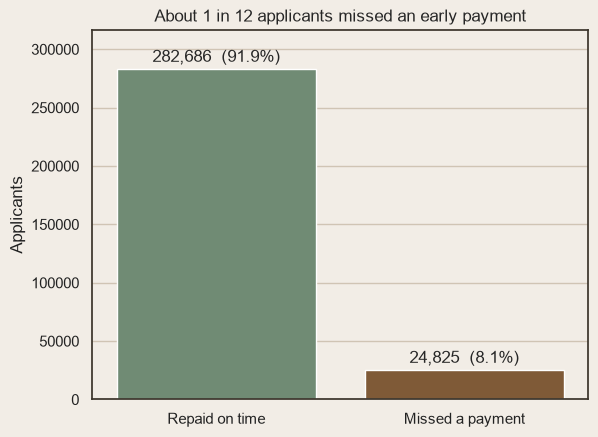

In [11]:
counts = df["Default"].map(OUTCOME).value_counts()
ax = sns.barplot(x=counts.index, y=counts.values, hue=counts.index, palette=earth_palette[:2], legend=False)
for bars, n in zip(ax.containers, counts.values):
    ax.bar_label(bars, labels=[f"{n:,}  ({n / len(df):.1%})"], padding=3)
ax.margins(y=0.12)
ax.set(xlabel="", ylabel="Applicants", title="About 1 in 12 applicants missed an early payment")
plt.show()

### Numbers, by outcome

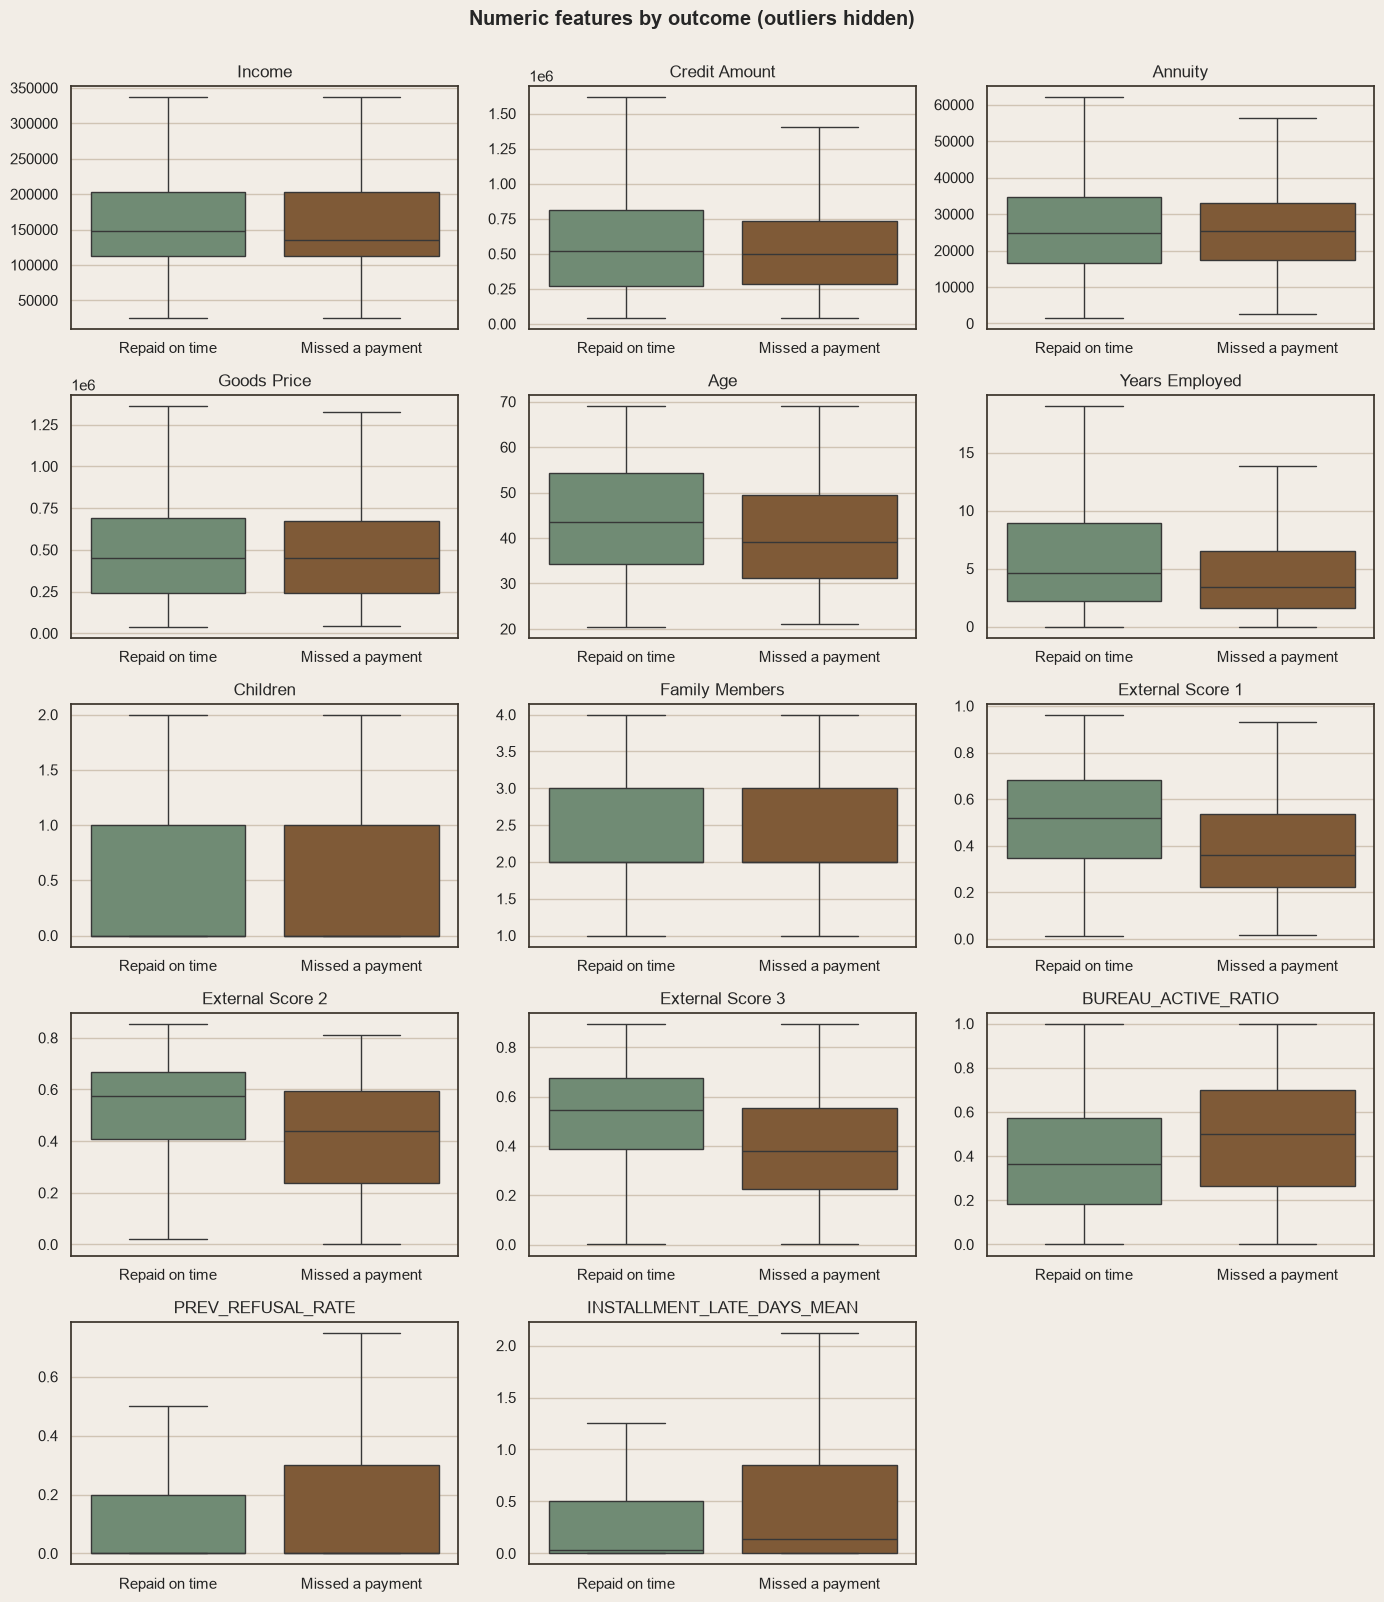

In [12]:
# The columns worth looking at. Plotting every numeric column would be unreadable.
num_cols = [
    'Income', 'Credit Amount', 'Annuity', 'Goods Price',
    'Age', 'Years Employed', 'Children', 'Family Members',
    'External Score 1', 'External Score 2', 'External Score 3',
    'BUREAU_ACTIVE_RATIO', 'PREV_REFUSAL_RATE', 'INSTALLMENT_LATE_DAYS_MEAN',
]
outcome = df["Default"].map(OUTCOME)

plt.figure(figsize=(14, 16))
for i, col in enumerate(num_cols, 1):
    plt.subplot((len(num_cols) + 2) // 3, 3, i)
    sns.boxplot(x=outcome, y=df[col], order=list(OUTCOME.values()), hue=outcome, hue_order=list(OUTCOME.values()),
                palette=earth_palette[:2], showfliers=False)
    plt.title(col)
    plt.xlabel("")
    plt.ylabel("")
plt.suptitle("Numeric features by outcome (outliers hidden)", fontweight="bold", y=1.0)
plt.tight_layout()
plt.savefig(f"{FIGURES}/boxplots.png", dpi=200, bbox_inches="tight")
plt.show()

### Categories

For each column: how common each value is, and how often those applicants missed a payment
compared with the 8.1% average. Groups under 1,000 applicants are left off, since a rate
from a handful of people is noise.

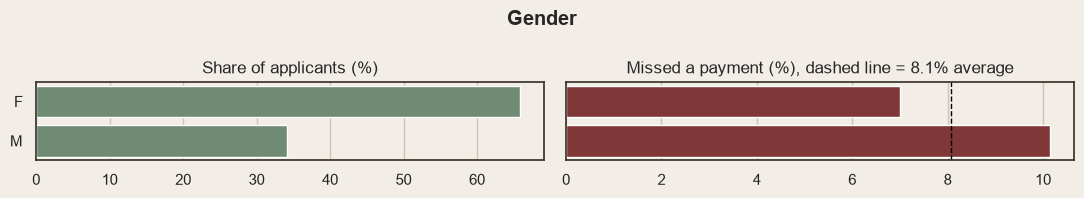

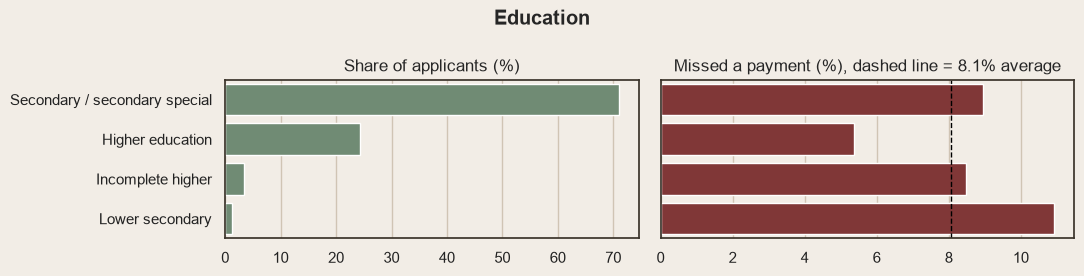

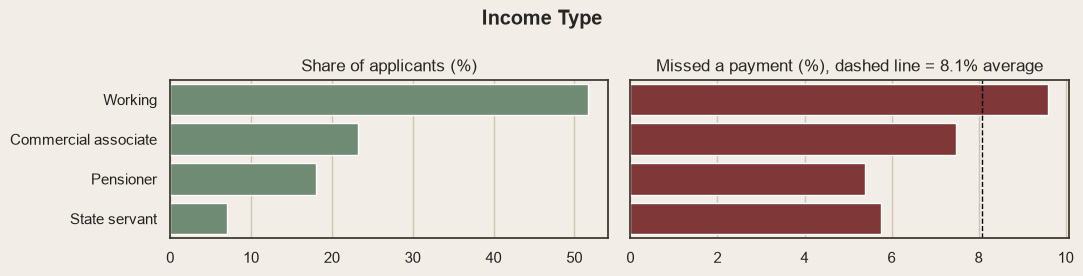

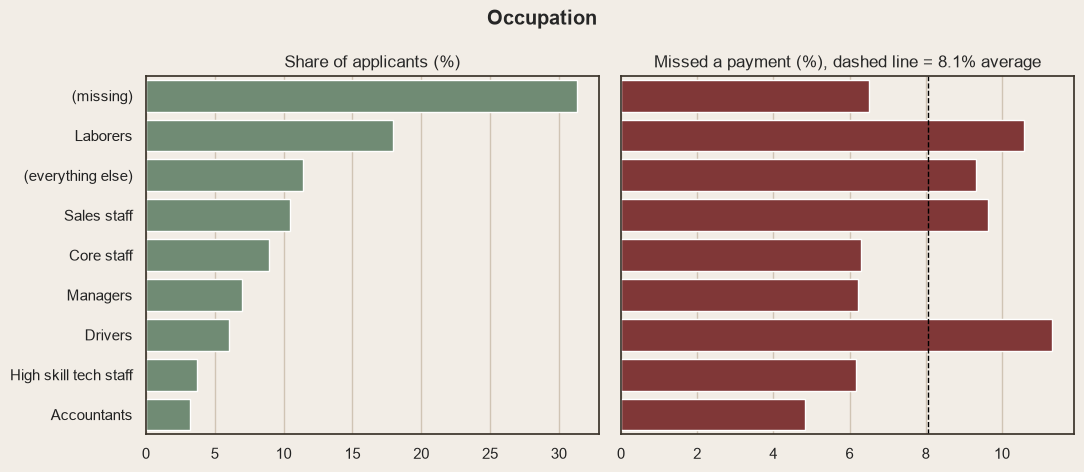

In [13]:
def category_profile(col, n=8, min_size=1000):
    """Share of applicants and miss rate for the n most common values of a column."""
    values = df[col].fillna("(missing)")
    values = values.where(values.isin(values.value_counts().index[:n]), "(everything else)")
    profile = df.groupby(values)["Default"].agg(applicants="size", rate="mean")
    profile = profile[profile["applicants"] >= min_size]
    profile["share"] = profile["applicants"] / len(df)
    return profile.sort_values("share", ascending=False)


average = df["Default"].mean()
cat_cols = ["Gender", "Education", "Income Type", "Occupation"]

for col in cat_cols:
    profile = category_profile(col)
    fig, (share, rate) = plt.subplots(1, 2, figsize=(11, 0.4 * len(profile) + 1.2), sharey=True)
    sns.barplot(x=profile["share"] * 100, y=profile.index, ax=share, color=earth_palette[0])
    share.set(title="Share of applicants (%)", xlabel="", ylabel="")
    sns.barplot(x=profile["rate"] * 100, y=profile.index, ax=rate, color=earth_palette[4])
    rate.axvline(average * 100, color="black", linestyle="--", linewidth=1)
    rate.set(title=f"Missed a payment (%), dashed line = {average:.1%} average", xlabel="", ylabel="")
    fig.suptitle(col, fontweight="bold")
    fig.tight_layout()
    plt.show()

### Correlations

In [14]:
# The ten strongest correlations with Default in each direction
corr_matrix = df.corr(numeric_only=True)
target_corr = corr_matrix["Default"].drop("Default").sort_values()
pd.concat([target_corr.tail(10)[::-1], target_corr.head(10)]).round(3).to_frame("correlation with Default")

,correlation with Default
CC_UTILIZATION_MEAN,0.136
BUREAU_DAYS_CREDIT_MEAN,0.090
CC_CNT_DRAWINGS_MEAN,0.083
DAYS_BIRTH,0.078
PREV_REFUSAL_RATE,0.078
BUREAU_ACTIVE_RATIO,0.077
DAYS_EMPLOYED,0.075
INSTALLMENT_LATE_RATE,0.070
PREV_APP_CREDIT_RATIO_MEAN,0.065
INSTALLMENT_UNDERPAID_RATE,0.063


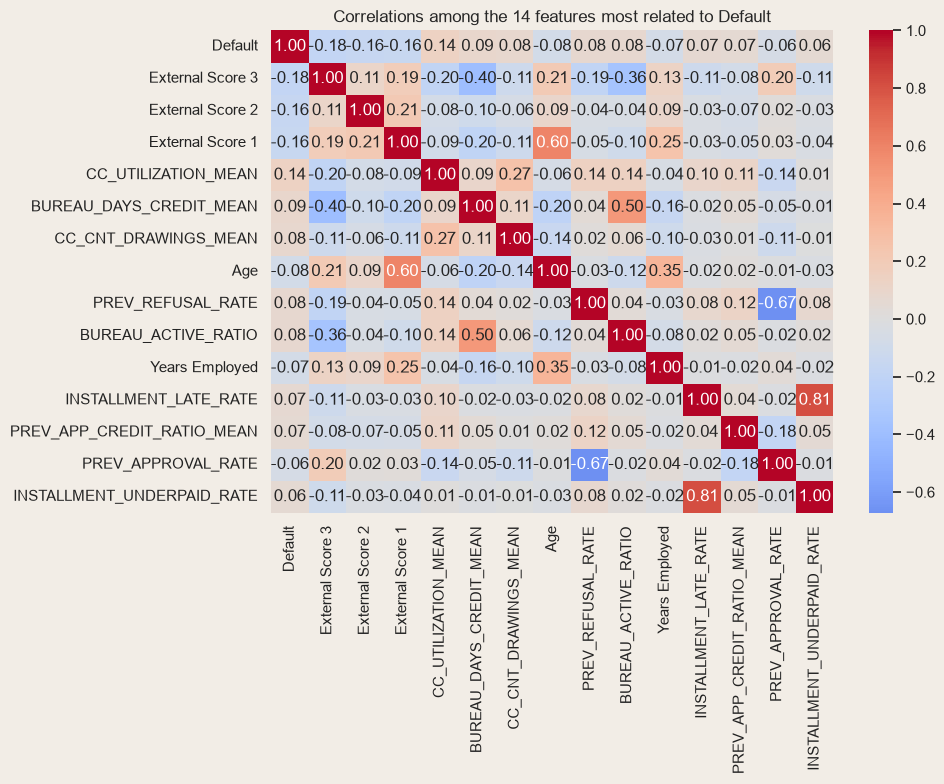

In [15]:
# DAYS_BIRTH and DAYS_EMPLOYED are Age and Years Employed counted in negative days, so
# they'd only show up as a duplicate at -1.00
strongest = corr_matrix["Default"].drop(["DAYS_BIRTH", "DAYS_EMPLOYED"]).abs().sort_values(ascending=False)
top_corr_cols = strongest.head(15).index

plt.figure(figsize=(10, 8))
sns.heatmap(df[top_corr_cols].corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Correlations among the 14 features most related to Default")
plt.tight_layout()
plt.savefig(f"{FIGURES}/correlations.png", dpi=200, bbox_inches="tight")
plt.show()

**What this shows.** The three external credit scores are the strongest signals: the higher
the score, the fewer missed payments (correlations of −0.16 to −0.18). Credit-card
utilisation (+0.14) and age (−0.08) come next. Each one is weak by itself, which is why the
models have to combine many of them.

Two things matter for the linear model in 02_research. External Score 1 rises with age
(correlation 0.60), and the building columns come in near-identical triplets (`_AVG`,
`_MEDI`, `_MODE`).

## 4. Save the table for 02_research

In [16]:
os.makedirs("cache", exist_ok=True)
df.to_parquet("cache/applications.parquet", index=False)
print(f"saved cache/applications.parquet  {df.shape}")

saved cache/applications.parquet  (307511, 164)


## 5. Numbers for the website

The findings page reads one small JSON file instead of 2.5 GB of CSVs. This writes it into
the frontend.

In [17]:
FINDINGS = "../frontend/public/data/site_findings.json"

app = pd.read_csv("../data/application_train.csv", usecols=[
    "TARGET", "EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "DAYS_BIRTH",
    "NAME_EDUCATION_TYPE", "NAME_INCOME_TYPE", "AMT_INCOME_TOTAL", "AMT_ANNUITY",
    "AMT_CREDIT", "CODE_GENDER", "NAME_CONTRACT_TYPE", "DAYS_EMPLOYED",
])


def rate_by(frame, groups):
    """Miss rate and count for each group, in group order."""
    g = frame.groupby(groups, observed=True)["TARGET"].agg(["mean", "size"])
    return [{"band": str(i), "rate": float(r["mean"]), "n": int(r["size"])} for i, r in g.iterrows()]


def rate_by_band(frame, col, bands, labels):
    return rate_by(frame, pd.cut(frame[col], bins=bands, labels=labels, include_lowest=True))


findings = {"n": int(len(app)), "miss_rate": float(app["TARGET"].mean())}

# The dominant signal: the three external bureau scores
app["ext_mean"] = app[["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]].mean(axis=1)
fifths = pd.qcut(app["ext_mean"], 5, labels=["lowest 20%", "2nd", "middle", "4th", "highest 20%"])
findings["by_ext_score"] = rate_by(app, fifths)
findings["ext_missing_rate"] = float(app["ext_mean"].isna().mean())

app["age"] = -app["DAYS_BIRTH"] / 365.25
findings["by_age"] = rate_by_band(app, "age", [0, 25, 30, 40, 50, 60, 100],
                                  ["under 25", "25-29", "30-39", "40-49", "50-59", "60+"])

# Affordability: the monthly payment as a share of monthly income
app["dsr"] = app["AMT_ANNUITY"] / app["AMT_INCOME_TOTAL"]
findings["by_dsr"] = rate_by_band(app, "dsr", [0, .10, .15, .20, .25, .30, 10],
                                  ["under 10%", "10-15%", "15-20%", "20-25%", "25-30%", "over 30%"])

edu = app.groupby("NAME_EDUCATION_TYPE", observed=True)["TARGET"].agg(["mean", "size"])
edu = edu[edu["size"] > 500].sort_values("mean")
findings["by_education"] = [{"band": str(i).replace(" / secondary special", ""),
                             "rate": float(r["mean"]), "n": int(r["size"])} for i, r in edu.iterrows()]

emp = app[app["DAYS_EMPLOYED"] != 365243].copy()
emp["yrs"] = -emp["DAYS_EMPLOYED"] / 365.25
findings["by_employment"] = rate_by_band(emp, "yrs", [0, 1, 3, 6, 11, 100],
                                         ["under 1yr", "1-3", "3-6", "6-11", "11+"])
findings["by_contract"] = rate_by(app, "NAME_CONTRACT_TYPE")

# What the money was actually for, from prior applications
prev = pd.read_csv("../data/previous_application.csv", usecols=["NAME_GOODS_CATEGORY", "CNT_PAYMENT"])
goods = prev["NAME_GOODS_CATEGORY"]
goods = goods[~goods.isin(["XNA", "XAP"])]
findings["goods"] = [{"band": str(i), "pct": float(v)}
                     for i, v in (goods.value_counts(normalize=True) * 100).head(8).items()]
term = prev["CNT_PAYMENT"].dropna()
term = term[term > 0]
findings["term"] = {"median": float(term.median()), "p90": float(term.quantile(.9)), "max": float(term.max())}

with open(FINDINGS, "w") as f:
    json.dump(findings, f, indent=2)

lo, hi = findings["by_ext_score"][0]["rate"], findings["by_ext_score"][-1]["rate"]
print(f"wrote {FINDINGS}")
print(f"  {findings['n']:,} applications, {findings['miss_rate']:.2%} missed an early payment")
print(f"  external score: lowest fifth {lo:.1%} vs highest fifth {hi:.1%} ({lo / hi:.1f}x)")
print(f"  median term {findings['term']['median']:.0f} months")

wrote ../frontend/public/data/site_findings.json
  307,511 applications, 8.07% missed an early payment
  external score: lowest fifth 18.7% vs highest fifth 2.5% (7.6x)
  median term 12 months


### The two strongest patterns

The bureau scores and age, drawn from the numbers above. The paper uses this chart.

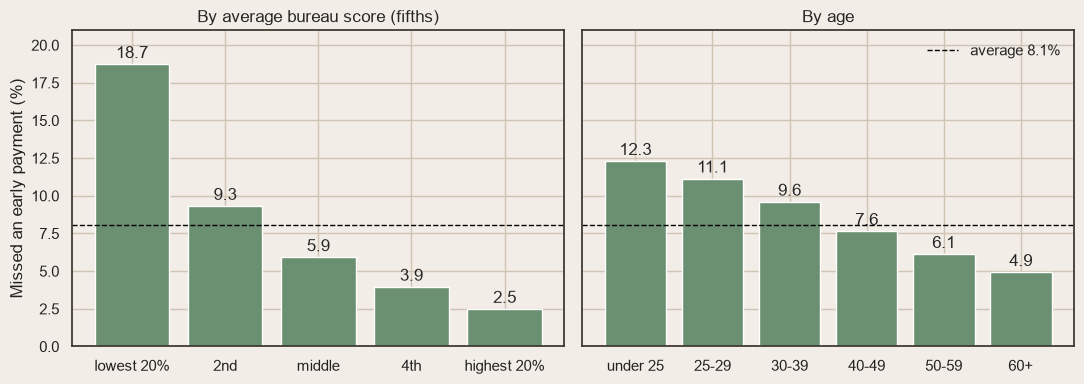

In [18]:
# Missed-payment rate by fifth of the average bureau score, and by age. Dashed line: the
# overall rate.
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, key, title in ((axes[0], "by_ext_score", "By average bureau score (fifths)"),
                       (axes[1], "by_age", "By age")):
    bands = pd.DataFrame(findings[key])
    bars = ax.bar(bands["band"], bands["rate"] * 100, color=earth_palette[0])
    ax.bar_label(bars, fmt="%.1f", padding=2)
    ax.axhline(findings["miss_rate"] * 100, color="black", linestyle="--", linewidth=1,
               label=f"average {findings['miss_rate']:.1%}")
    ax.set(title=title, xlabel="")
    ax.margins(y=0.12)
axes[0].set_ylabel("Missed an early payment (%)")
axes[1].legend(loc="upper right", frameon=False)
plt.tight_layout()
plt.savefig(f"{FIGURES}/eda_rates.png", dpi=200, bbox_inches="tight")
plt.show()